# Task 2: Content Type Analysis Dashboard 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
df = pd.read_csv("C:/Users/Admin/Downloads/Auspify Tech Internship/dataset_cleaned.csv")

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
# Calculating content counts
df["type"].value_counts()

type
Movie      6126
Tv Show    2664
Name: count, dtype: int64

In [4]:
# Calculating content percentages
type_counts = df["type"].value_counts()

type_percentages = (type_counts / type_counts.sum()) * 100

print(type_percentages.round(2))

type
Movie      69.69
Tv Show    30.31
Name: count, dtype: float64


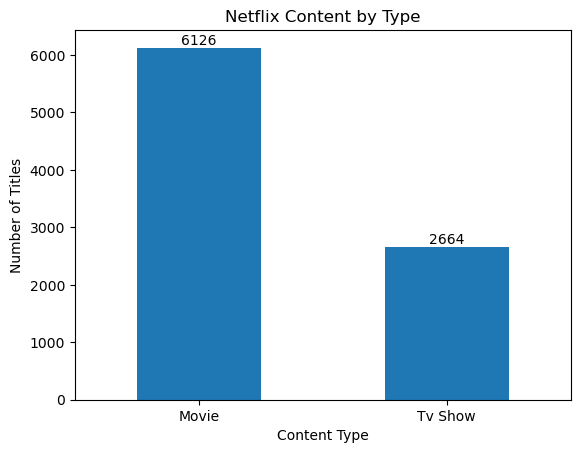

In [6]:
# Content Distribution bar chart
ax = type_counts.plot(kind="bar")

plt.title("Netflix Content by Type")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)

ax.bar_label(ax.containers[0])

plt.show()

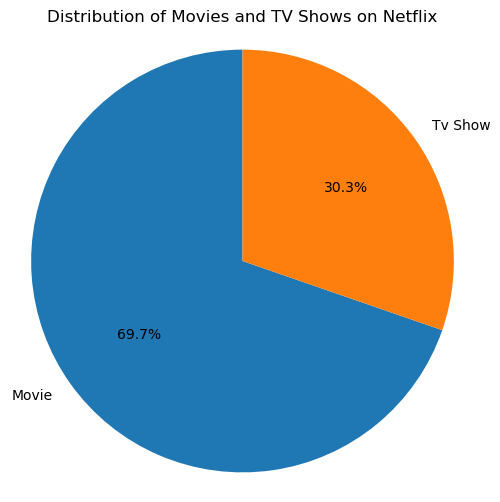

In [10]:
# Content Proportion pie chart 

plt.figure(figsize=(6,6))

plt.pie(
    type_counts.values,
    labels=type_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Distribution of Movies and TV Shows on Netflix")

plt.axis('equal')   # Keeps the pie chart circular

plt.show()

### Task 2 findings

- Movies account for **6,126 titles (69.69%)**.
- TV Shows account for **2,664 titles (30.31%)**.
- The catalog in this dataset is therefore movie-heavy. This describes the dataset's content mix; it does not by itself prove which format performs better with viewers, because viewership, completion, and engagement data are not included.

**Business implication:** If the goal is to understand catalog composition, Movies are the dominant format. Decisions about investing in more Movies or TV Shows should not be made from title counts alone; audience engagement and cost/performance data would also be needed.

# TASK 3:  Country-Wise Netflix Content Analysis

In [11]:
# Extract and clean country information

print(df["country"].nunique())          # how many different values?
print(df["country"].isna().sum())       # how many empty cells?
print(df["country"].value_counts().head(10))   # the most common values

86
0
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64


In [12]:
print(df["country"].str.contains(",").sum())                      # several countries in one cell?
print((df["country"] != df["country"].str.strip()).sum())         # stray spaces?
print(df["country"].str.title().nunique())                        # different capitalisations?

0
0
86


In [13]:
# Handle 'Not Given'
df["country_clean"] = df["country"].str.strip().str.title()
df["country_clean"] = df["country_clean"].replace("Not Given", pd.NA)

known = df.dropna(subset=["country_clean"])
print(len(df), len(known))

8790 8503


In [14]:
# Calculate content by country(value counts)
country_counts = known["country_clean"].value_counts()
print(country_counts.head(10))

country_clean
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


In [15]:
# Calculate content by country(group by)
country_counts = (
    known.groupby("country_clean")   # 1. split the rows into one group per country
         .size()                     # 2. count the rows in each group
         .sort_values(ascending=False)   # 3. biggest first
)
print(country_counts.head(10))

country_clean
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
dtype: int64


In [16]:
# Content by country in percentage
summary = pd.DataFrame({
    "titles": country_counts,
    "percent": (country_counts / len(known) * 100).round(1)
})
print(summary.head(10))
print(country_counts.size)   # how many countries in total

                titles  percent
country_clean                  
United States     3240     38.1
India             1057     12.4
United Kingdom     638      7.5
Pakistan           421      5.0
Canada             271      3.2
Japan              259      3.0
South Korea        214      2.5
France             213      2.5
Spain              182      2.1
Mexico             138      1.6
85


In [17]:
# Identify top 10 content producing countries 
top10 = country_counts.head(10)

cumulative = (top10 / len(known) * 100).cumsum().round(1)
print(cumulative)

country_clean
United States     38.1
India             50.5
United Kingdom    58.0
Pakistan          63.0
Canada            66.2
Japan             69.2
South Korea       71.7
France            74.2
Spain             76.4
Mexico            78.0
dtype: float64


In [18]:
# Create a rankings table
ranking = summary.head(10).reset_index()
ranking.columns = ["Country", "Titles", "Percent"]
ranking.index = ranking.index + 1      # start rank at 1, not 0
print(ranking)

           Country  Titles  Percent
1    United States    3240     38.1
2            India    1057     12.4
3   United Kingdom     638      7.5
4         Pakistan     421      5.0
5           Canada     271      3.2
6            Japan     259      3.0
7      South Korea     214      2.5
8           France     213      2.5
9            Spain     182      2.1
10          Mexico     138      1.6


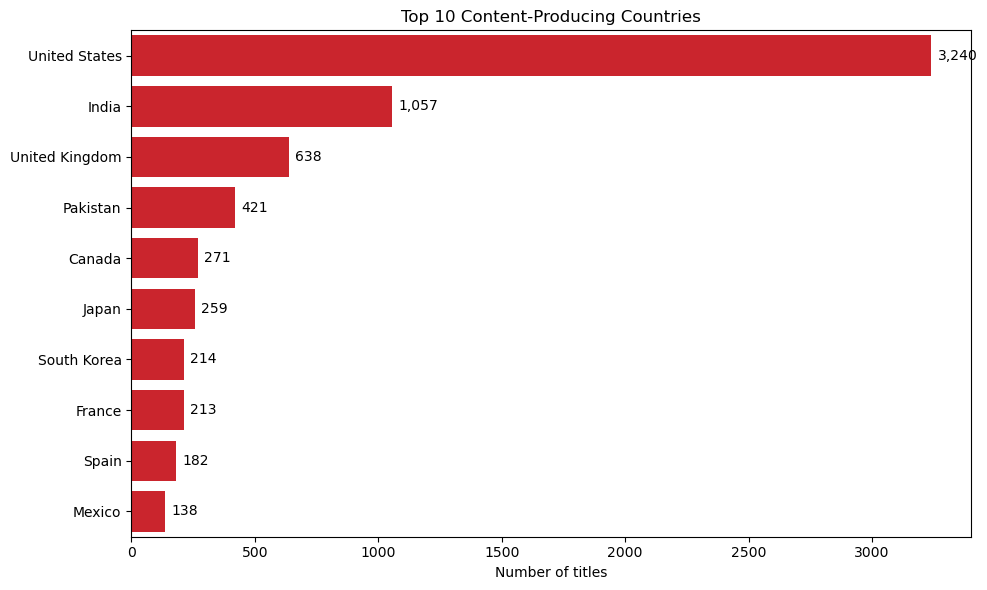

In [19]:
# Bar chart of the top 10

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(y=top10.index, x=top10.values, color="#E50914", ax=ax)

for i, v in enumerate(top10.values):
    ax.text(v + 25, i, f"{v:,}", va="center")      # write the count at the end of each bar

ax.set(title="Top 10 Content-Producing Countries", xlabel="Number of titles", ylabel="")
plt.tight_layout()
plt.show()

type            Movie  TV Show
country_clean                 
United States    2395      845
India             976       81
United Kingdom    387      251
Pakistan           71      350
Canada            187       84
Japan              87      172
South Korea        49      165
France            148       65
Spain             129       53
Mexico             90       48


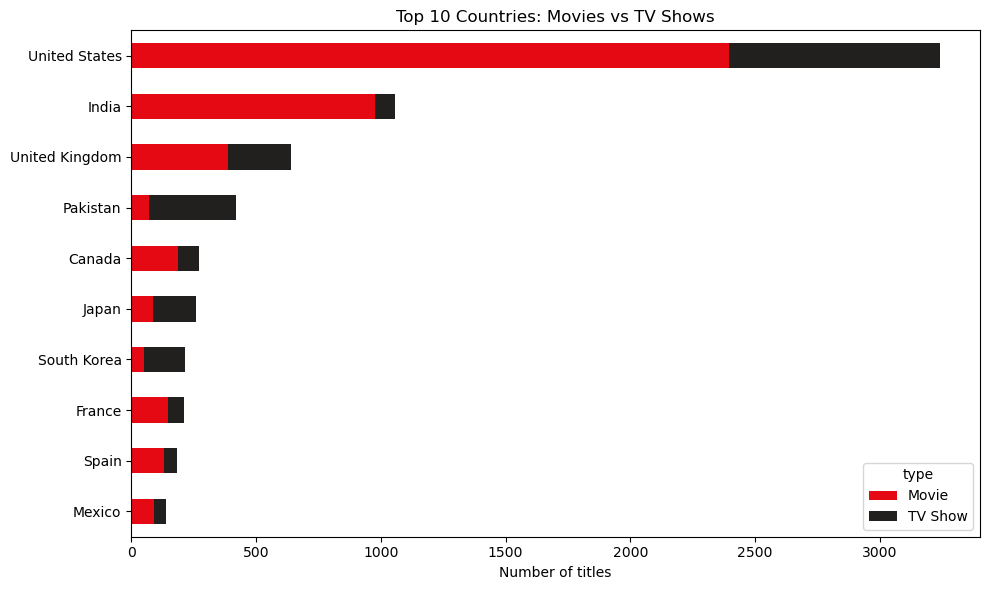

In [20]:
# Movies and TV shows within each country
known = known.copy()
known["type"] = known["type"].replace("Tv Show", "TV Show")   # fix the casing from cleaning

by_type = (
    known[known["country_clean"].isin(top10.index)]   # keep only top-10 countries
         .groupby(["country_clean", "type"]).size()    # count per country AND type
         .unstack(fill_value=0)                        # turn type into columns
         .loc[top10.index]                             # keep the ranking order
)
print(by_type)

by_type.plot(kind="barh", stacked=True, figsize=(10, 6), color=["#E50914", "#221F1F"])
plt.gca().invert_yaxis()                               # put #1 at the top
plt.title("Top 10 Countries: Movies vs TV Shows")
plt.xlabel("Number of titles")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Business Insights

#### Insight 1: The catalogue is concentrated in a few markets

The United States, India and the United Kingdom together account for about 58% of titles with a known country, and the top 10 countries account for 78%. The other 75 countries share just 22%.Netflix’s catalogue depends heavily on a few markets. Viewers in smaller markets see little local content, and any change in those few markets would affect a large part of the library. Netflix could grow local content in the long tail of smaller countries to widen the catalogue.

#### Insight 2: Content type differs a lot between countries

Pakistan, South Korea and Japan have catalogues made up mostly of TV shows. India is the opposite, with only about 8% TV shows and the rest movies.
Different countries contribute different formats, so Netflix’s catalogue is not made of one uniform product. Series may keep viewers coming back from one episode to the next, while films suit one-off viewing. This is a hypothesis from outside the data.
The dataset has no viewership or revenue figures, so we can’t say which format performs better. Before deciding where to invest, Netflix would need engagement data for each country and format.